Data: X_train.csv, y_train.csv, X_test.csv, y_test.csv, aur saved models (logreg_pipeline.joblib, decision_tree_tuned.joblib). Yeh test Week 15 (Day 71-75) cover karta hai.

Test ke rules (yeh bhi test ka hissa hain):

- Model aur threshold ka chunav sirf CV ke out-of-fold predictions se hoga (StratifiedKFold(5, shuffle=True, random_state=42)).
- Test set par final numbers sirf ek baar nikalne hain, aur dekh kar kuch badalna nahi hai.
- Har metric ke saath ek baseline ka number bhi dikhana hai.

Section A: Confusion Matrix (Day 71)

1. Is example ke liye TN, FP, FN, TP pehle haath se gino, phir confusion_matrix().ravel() se verify karo:
actual = [1,1,1,0,0,0,0,1,0,0], predicted = [1,0,1,0,1,0,0,1,0,0]

In [1]:

from pathlib import Path
import math
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, fbeta_score,
    mean_absolute_error, mean_squared_error, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve, r2_score,
)
from sklearn.model_selection import (
    KFold, StratifiedKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

HERE = Path.cwd()
PROJECT = HERE.parent if HERE.name == "notebooks" else HERE
DATA = PROJECT / "data" / "processed"
MODEL_DIR = PROJECT / "notebooks" / "models"
X_train = pd.read_csv(DATA / "X_train.csv")
X_test = pd.read_csv(DATA / "X_test.csv")
y_train = pd.read_csv(DATA / "y_train.csv").squeeze().astype(int)
y_test = pd.read_csv(DATA / "y_test.csv").squeeze().astype(int)
models = {
    "Logistic Regression": joblib.load(MODEL_DIR / "logreg_pipeline.joblib"),
    "Tuned Decision Tree": joblib.load(MODEL_DIR / "decision_tree_tuned.joblib"),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

def _threshold_f1(y, score):
    precision, recall, thresholds = precision_recall_curve(y, score)
    values = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-15)
    i = int(np.nanargmax(values))
    return float(thresholds[i]), float(values[i])

def _threshold_youden(y, score):
    fpr, tpr, thresholds = roc_curve(y, score)
    valid = np.isfinite(thresholds)
    return float(thresholds[valid][np.argmax((tpr - fpr)[valid])])

def _scores(y, pred, score):
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, score),
        "avg_precision": average_precision_score(y, score),
    }

def _net_value(y, pred, cost_fn=50, cost_fp=5, benefit_tp=40):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return float(benefit_tp * tp - cost_fp * fp - cost_fn * fn)

def evaluate_classifier(model, X_tr, y_tr, X_te, y_te, cv,
                        cost_fn=50, cost_fp=5, benefit_tp=40):
    """CV summaries and OOF-selected thresholds; test predictions are generated once."""
    fold = cross_validate(
        clone(model), X_tr, y_tr, cv=cv, scoring=METRICS, n_jobs=1
    )
    oof_probability = cross_val_predict(
        clone(model), X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=1
    )[:, 1]
    oof_prediction = cross_val_predict(
        clone(model), X_tr, y_tr, cv=cv, method="predict", n_jobs=1
    )
    threshold_f1, oof_best_f1 = _threshold_f1(y_tr, oof_probability)
    threshold_youden = _threshold_youden(y_tr, oof_probability)

    fitted = clone(model).fit(X_tr, y_tr)
    test_probability = fitted.predict_proba(X_te)[:, 1]
    test_prediction = (test_probability >= 0.5).astype(int)
    test_prediction_f1 = (test_probability >= threshold_f1).astype(int)
    test_prediction_youden = (test_probability >= threshold_youden).astype(int)
    return {
        "fold": fold,
        "cv_metrics": {metric: {"mean": float(np.mean(fold[f"test_{metric}"])),
                        "std": float(np.std(fold[f"test_{metric}"], ddof=1))}
                       for metric in METRICS},
        "oof_probability": oof_probability,
        "oof_prediction": oof_prediction,
        "threshold_f1": threshold_f1,
        "oof_best_f1": oof_best_f1,
        "threshold_youden": threshold_youden,
        "test_probability": test_probability,
        "test_prediction": test_prediction,
        "test_prediction_f1": test_prediction_f1,
        "test_prediction_youden": test_prediction_youden,
        "test_metrics": _scores(y_te, test_prediction, test_probability),
        "test_metrics_f1": _scores(y_te, test_prediction_f1, test_probability),
        "test_metrics_youden": _scores(y_te, test_prediction_youden, test_probability),
        "test_net_value_f1": _net_value(
            y_te, test_prediction_f1, cost_fn, cost_fp, benefit_tp
        ),
        "test_net_value_default": _net_value(
            y_te, test_prediction, cost_fn, cost_fp, benefit_tp
        ),
    }

results = {
    name: evaluate_classifier(model, X_train, y_train, X_test, y_test, cv)
    for name, model in models.items()
}
dummy_models = {
    "Dummy majority": DummyClassifier(strategy="most_frequent"),
    "Dummy always churn": DummyClassifier(strategy="constant", constant=1),
}
dummy_results = {
    name: evaluate_classifier(model, X_train, y_train, X_test, y_test, cv)
    for name, model in dummy_models.items()
}
oof_prob = {name: result["oof_probability"] for name, result in results.items()}
oof_pred = {name: result["oof_prediction"] for name, result in results.items()}
test_prob = {name: result["test_probability"] for name, result in results.items()}
test_pred = {name: result["test_prediction"] for name, result in results.items()}
f1_threshold = {name: result["threshold_f1"] for name, result in results.items()}
youden_threshold = {name: result["threshold_youden"] for name, result in results.items()}
test_metrics = {name: result["test_metrics"] for name, result in results.items()}
test_metrics_f1 = {name: result["test_metrics_f1"] for name, result in results.items()}
print(f"Train: {X_train.shape}; test: {X_test.shape}")
print(f"Train prevalence: {y_train.mean():.3%}; test prevalence: {y_test.mean():.3%}")
print("OOF-only F1 thresholds:", f1_threshold)
print("OOF-only Youden thresholds:", youden_threshold)
print("All test predictions and final test metrics are cached; do not tune on test.")


Train: (4226, 8); test: (1057, 8)
Train prevalence: 56.626%; test prevalence: 56.575%
OOF-only F1 thresholds: {'Logistic Regression': 0.28893519422852054, 'Tuned Decision Tree': 0.30048074026772004}
OOF-only Youden thresholds: {'Logistic Regression': 0.4942810106937692, 'Tuned Decision Tree': 0.4736162427807873}
All test predictions and final test metrics are cached; do not tune on test.


2. Apne LogReg aur tuned Decision Tree ka test confusion matrix banao (heatmap, counts aur row-normalized dono). Total TN+FP+FN+TP test set ke size ke barabar hai, yeh code se assert karo.

3. cross_val_predict se X_train ka out-of-fold confusion matrix dono models ke liye nikaalo. Test matrix se compare karo. Kaunsa zyada bharosemand hai aur kyun?

4. Apne project ke liye FP aur FN ki cost ke assumptions likho (rupees/pounds mein, reason ke saath). Un costs se dono models ki net value nikaalo. Kya business ke hisaab se “best model” accuracy wale best model se alag nikla?

Q1 manual counts: {'TN': 5, 'FP': 1, 'FN': 1, 'TP': 3}
Q1 sklearn TN, FP, FN, TP: [5 1 1 3]


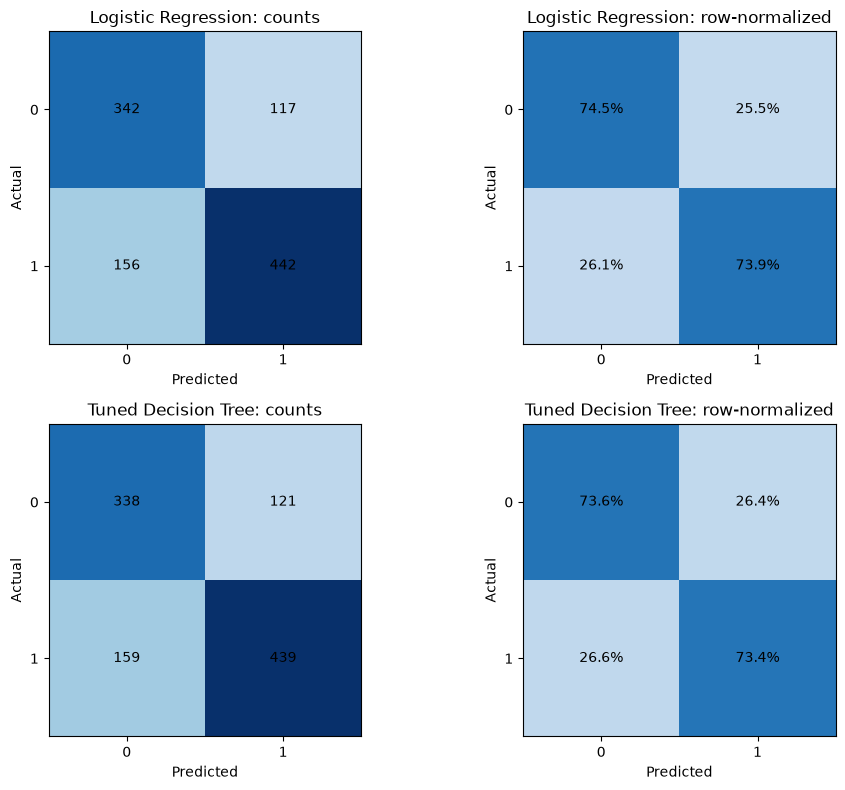

,model,"OOF TN,FP,FN,TP","test TN,FP,FN,TP",default test accuracy,default test net value (£)
0,Logistic Regression,"[1327, 506, 670, 1723]","[342, 117, 156, 442]",0.741722,9295.0
1,Tuned Decision Tree,"[1242, 591, 609, 1784]","[338, 121, 159, 439]",0.735099,9005.0


,model,test net value at CV F1 threshold (£),test accuracy at CV F1 threshold,test accuracy at 0.5
0,Logistic Regression,18720.0,0.707663,0.741722
1,Tuned Decision Tree,19160.0,0.710501,0.735099


,baseline,net value (£)
0,Dummy majority,21625.0
1,Dummy always churn,21625.0


At default 0.5, accuracy and net value rank the models alike: Logistic Regression (net values: LogReg £9295, Tree £9005). At CV F1 thresholds, net-value winner=Tuned Decision Tree (Tree £19160; LogReg £18720); always-churn baseline gives £21625. So the threshold changes the model comparison, and the simple baseline is best overall under these stated costs.


**Q3–4.** OOF confusion counts use each training customer's prediction from a fold that excluded that customer; they are the more stable choice for model comparison/threshold choice because all training rows contribute without fitting on their own labels. The test matrix is the independent final check, but has fewer rows and must not guide changes. Assumptions: an FN costs **£50** in expected lost contribution/retention opportunity; an FP costs **£5** in unnecessary contact/offer expense; a TP yields **£40** in expected retained contribution. Net value = £40·TP − £5·FP − £50·FN (TN has no incremental value). These are explicit teaching assumptions, not observed accounting amounts. Compare the displayed value ranking with accuracy; cost-weighted and accuracy winners can differ.

In [2]:

actual = np.array([1, 1, 1, 0, 0, 0, 0, 1, 0, 0])
predicted = np.array([1, 0, 1, 0, 1, 0, 0, 1, 0, 0])
manual = {
    "TN": int(np.sum((actual == 0) & (predicted == 0))),
    "FP": int(np.sum((actual == 0) & (predicted == 1))),
    "FN": int(np.sum((actual == 1) & (predicted == 0))),
    "TP": int(np.sum((actual == 1) & (predicted == 1))),
}
print("Q1 manual counts:", manual)
print("Q1 sklearn TN, FP, FN, TP:", confusion_matrix(actual, predicted).ravel())

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, name in enumerate(models):
    cm = confusion_matrix(y_test, test_pred[name], labels=[0, 1])
    assert cm.sum() == len(y_test) == len(X_test)
    row_cm = confusion_matrix(y_test, test_pred[name], labels=[0, 1], normalize="true")
    for ax, matrix, fmt, title in [
        (axes[row, 0], cm, "d", f"{name}: counts"),
        (axes[row, 1], row_cm, ".1%", f"{name}: row-normalized"),
    ]:
        ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(1, matrix.max()))
        ax.set_xticks([0, 1], labels=["0", "1"])
        ax.set_yticks([0, 1], labels=["0", "1"])
        ax.set(title=title, xlabel="Predicted", ylabel="Actual")
        for i in range(2):
            for j in range(2):
                label = format(matrix[i, j], fmt) if fmt == "d" else f"{matrix[i, j]:.1%}"
                ax.text(j, i, label, ha="center", va="center")
plt.tight_layout()
plt.show()

cm_rows = []
for name in models:
    oof_cm = confusion_matrix(y_train, oof_pred[name], labels=[0, 1])
    test_cm = confusion_matrix(y_test, test_pred[name], labels=[0, 1])
    cm_rows.append({"model": name, "OOF TN,FP,FN,TP": oof_cm.ravel().tolist(),
                    "test TN,FP,FN,TP": test_cm.ravel().tolist(),
                    "default test accuracy": accuracy_score(y_test, test_pred[name]),
                    "default test net value (£)": _net_value(y_test, test_pred[name])})
display(pd.DataFrame(cm_rows))
display(pd.DataFrame([
    {"model": name, "test net value at CV F1 threshold (£)": results[name]["test_net_value_f1"],
     "test accuracy at CV F1 threshold": results[name]["test_metrics_f1"]["accuracy"],
     "test accuracy at 0.5": results[name]["test_metrics"]["accuracy"]}
    for name in models
]))
display(pd.DataFrame([
    {"baseline": name, "net value (£)": result["test_net_value_default"]}
    for name, result in dummy_results.items()
]))
accuracy_winner = max(models, key=lambda name: results[name]["test_metrics"]["accuracy"])
value_winner = max(models, key=lambda name: results[name]["test_net_value_default"])
f1_value_winner = max(models, key=lambda name: results[name]["test_net_value_f1"])
print(f"At default 0.5, accuracy and net value rank the models alike: {accuracy_winner} "
      f"(net values: LogReg £{results['Logistic Regression']['test_net_value_default']:.0f}, "
      f"Tree £{results['Tuned Decision Tree']['test_net_value_default']:.0f}). "
      f"At CV F1 thresholds, net-value winner={f1_value_winner} "
      f"(Tree £{results['Tuned Decision Tree']['test_net_value_f1']:.0f}; "
      f"LogReg £{results['Logistic Regression']['test_net_value_f1']:.0f}); "
      f"always-churn baseline gives £{dummy_results['Dummy always churn']['test_net_value_default']:.0f}. "
      "So the threshold changes the model comparison, and the simple baseline is best overall under these stated costs.")
accuracy_winner = max(models, key=lambda name: results[name]["test_metrics"]["accuracy"])
value_winner = max(models, key=lambda name: results[name]["test_net_value_default"])
display(Markdown(
    "**Q3–4.** OOF confusion counts use each training customer's prediction from a fold that excluded that customer; "
    "they are the more stable choice for model comparison/threshold choice because all training rows contribute "
    "without fitting on their own labels. The test matrix is the independent final check, but has fewer rows and "
    "must not guide changes. Assumptions: an FN costs **£50** in expected lost contribution/retention opportunity; "
    "an FP costs **£5** in unnecessary contact/offer expense; a TP yields **£40** in expected retained contribution. "
    "Net value = £40·TP − £5·FP − £50·FN (TN has no incremental value). These are explicit teaching assumptions, "
    "not observed accounting amounts. Compare the displayed value ranking with accuracy; cost-weighted and accuracy "
    "winners can differ."
))


Section B: Accuracy aur Precision (Day 72)

5. Test set par accuracy aur precision ko formula se manually nikaalo aur sklearn se match karo. zero_division ka kya matlab hai, ek line mein likho.

6. DummyClassifier ke do versions banao (“hamesha majority”, “hamesha churn”) aur unka accuracy/precision nikaalo. Dono se kya seekha?

7. Apne models ka lift (precision / prevalence) aur balanced accuracy nikaalo. Lift 1.0 ka kya matlab hota hai?

8. LogReg ke probabilities se precision@k table banao (top 5%, 10%, 20%, 30% customers). Agar budget sirf top 10% ka hai, to kitne churners pakde jayenge?

In [3]:

name = "Logistic Regression"
pred = test_pred[name]
tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
manual_accuracy = (tp + tn) / (tp + tn + fp + fn)
manual_precision = tp / (tp + fp) if tp + fp else 0.0
print(f"Q5 manual accuracy=(TP+TN)/N={manual_accuracy:.4f}; sklearn={accuracy_score(y_test, pred):.4f}")
print(f"Q5 manual precision=TP/(TP+FP)={manual_precision:.4f}; sklearn={precision_score(y_test, pred, zero_division=0):.4f}")
print("zero_division=0 returns 0 (instead of a warning/undefined value) when the precision denominator is zero.")

baseline_rows = []
for baseline_name, result in dummy_results.items():
    p = result["test_prediction"]
    baseline_rows.append({"baseline": baseline_name, **_scores(y_test, p, result["test_probability"])})
display(pd.DataFrame(baseline_rows).set_index("baseline").round(4))
majority_class = int(y_train.mode().iloc[0])
print(f"Majority baseline predicts class {majority_class}; always-churn predicts class 1. "
      f"Here churn is the majority ({y_train.mean():.1%}), so both baselines make identical predictions. "
      "This shows that majority accuracy depends on which class dominates, while the always-churn baseline "
      "has recall 1.0 but precision equal to prevalence.")

prevalence = y_test.mean()
metric_rows = []
for model_name, result in results.items():
    scores = result["test_metrics"]
    metric_rows.append({"model": model_name, "precision": scores["precision"],
                        "lift": scores["precision"] / prevalence,
                        "balanced accuracy": balanced_accuracy_score(y_test, result["test_prediction"])})
for baseline_name, result in dummy_results.items():
    scores = result["test_metrics"]
    metric_rows.append({"model": baseline_name, "precision": scores["precision"],
                        "lift": scores["precision"] / prevalence if prevalence else np.nan,
                        "balanced accuracy": balanced_accuracy_score(y_test, result["test_prediction"])})
display(pd.DataFrame(metric_rows).round(4))
print("Lift=1 means the selected customers churn at exactly the population prevalence: no enrichment over random selection.")

def top_k_table(y, score, percentages=(5, 10, 20, 30)):
    order = np.argsort(-np.asarray(score), kind="stable")
    positives = int(np.sum(y))
    rows = []
    for pct in percentages:
        k = max(1, int(np.ceil(len(y) * pct / 100)))
        captured = int(np.asarray(y)[order[:k]].sum())
        rows.append({"top_percent": pct, "customers_contacted": k,
                     "churners_captured": captured,
                     "precision_at_k": captured / k,
                     "recall_at_k": captured / positives if positives else 0.0,
                     "baseline_precision_at_k": float(np.mean(y)),
                     "baseline_recall_at_k": pct / 100})
    return pd.DataFrame(rows)

precision_k = top_k_table(y_test.to_numpy(), test_prob["Logistic Regression"])
display(precision_k.round(4))
top10 = precision_k.loc[precision_k["top_percent"] == 10].iloc[0]
print(f"At a top-10% budget, contact {int(top10.customers_contacted)} customers and capture "
      f"{int(top10.churners_captured)} of {int(y_test.sum())} test churners.")


Q5 manual accuracy=(TP+TN)/N=0.7417; sklearn=0.7417
Q5 manual precision=TP/(TP+FP)=0.7907; sklearn=0.7907
zero_division=0 returns 0 (instead of a warning/undefined value) when the precision denominator is zero.


,accuracy,precision,recall,f1,roc_auc,avg_precision
baseline,,,,,,
Dummy majority,0.5658,0.5658,1.0,0.7227,0.5,0.5658
Dummy always churn,0.5658,0.5658,1.0,0.7227,0.5,0.5658


Majority baseline predicts class 1; always-churn predicts class 1. Here churn is the majority (56.6%), so both baselines make identical predictions. This shows that majority accuracy depends on which class dominates, while the always-churn baseline has recall 1.0 but precision equal to prevalence.


,model,precision,lift,balanced accuracy
0,Logistic Regression,0.7907,1.3976,0.7421
1,Tuned Decision Tree,0.7839,1.3856,0.7352
2,Dummy majority,0.5658,1.0000,0.5000
3,Dummy always churn,0.5658,1.0000,0.5000


Lift=1 means the selected customers churn at exactly the population prevalence: no enrichment over random selection.


,top_percent,customers_contacted,churners_captured,precision_at_k,recall_at_k,baseline_precision_at_k,baseline_recall_at_k
0,5,53,51,0.9623,0.0853,0.5658,0.05
1,10,106,97,0.9151,0.1622,0.5658,0.10
2,20,212,185,0.8726,0.3094,0.5658,0.20
3,30,318,266,0.8365,0.4448,0.5658,0.30


At a top-10% budget, contact 106 customers and capture 97 of 598 test churners.


Section C: Recall aur F1 (Day 73)

9. F1 formula manually apply karo aur sklearn se match karo. Phir precision=1.0, recall=0.01 ke liye arithmetic mean aur F1 compare karo. Harmonic mean yahan kya batata hai?

10. classification_report dono models ke liye banao. macro avg aur weighted avg mein fark kya hai?

11. Precision, Recall aur F1 ko threshold ke saath plot karo (CV out-of-fold probabilities par). F1-best threshold nikaalo, phir test set par default 0.5 aur CV-chuna threshold dono ka result ek table mein dikhao.

12. Recall@k table banao (top 5%, 10%, 20%, 30%) aur sawal 8 ke precision@k ke saath ek hi chart mein plot karo. Dono ko saath padh kar ek business recommendation likho.

13. Test set ke recall ka 95% Wilson confidence interval nikaalo. Test mein kitne churners hain aur interval kitna chaura hai?

14. fbeta_score se F0.5, F1 aur F2 nikaalo. Tumhare project mein kaunsa beta sahi hai aur kyun?

Section D: ROC-AUC (Day 74)

15. AUC ko pairwise ranking se khud nikaalo (churner ka score active se zyada hone ki probability) aur roc_auc_score se match karo.

Q9 manual F1=2PR/(P+R)=0.7640; sklearn=0.7640
For precision=1.00 and recall=.01: arithmetic mean=0.505; F1=0.0198. The harmonic mean stays low because almost all actual churners are missed.
Q10 Logistic Regression classification report
              precision    recall  f1-score   support

           0       0.69      0.75      0.71       459
           1       0.79      0.74      0.76       598

    accuracy                           0.74      1057
   macro avg       0.74      0.74      0.74      1057
weighted avg       0.75      0.74      0.74      1057

Q10 Tuned Decision Tree classification report
              precision    recall  f1-score   support

           0       0.68      0.74      0.71       459
           1       0.78      0.73      0.76       598

    accuracy                           0.74      1057
   macro avg       0.73      0.74      0.73      1057
weighted avg       0.74      0.74      0.74      1057

Macro average weights each class equally; weighted average weigh

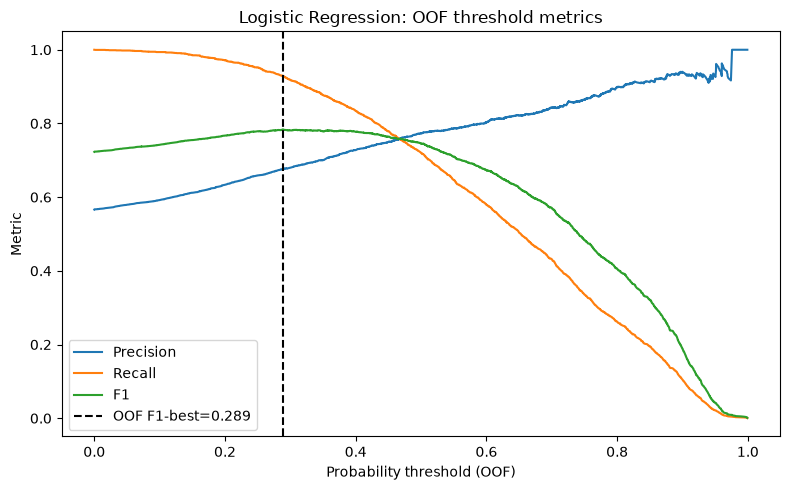

,accuracy,precision,recall,f1,roc_auc,avg_precision
threshold_rule,,,,,,
default 0.5,0.7417,0.7907,0.7391,0.7640,0.8094,0.8333
OOF F1-best (0.289),0.7077,0.6760,0.9281,0.7822,0.8094,0.8333


,top_percent,customers_contacted,churners_captured,precision_at_k,recall_at_k,baseline_precision_at_k,baseline_recall_at_k
0,5,53,51,0.9623,0.0853,0.5658,0.05
1,10,106,97,0.9151,0.1622,0.5658,0.10
2,20,212,185,0.8726,0.3094,0.5658,0.20
3,30,318,266,0.8365,0.4448,0.5658,0.30


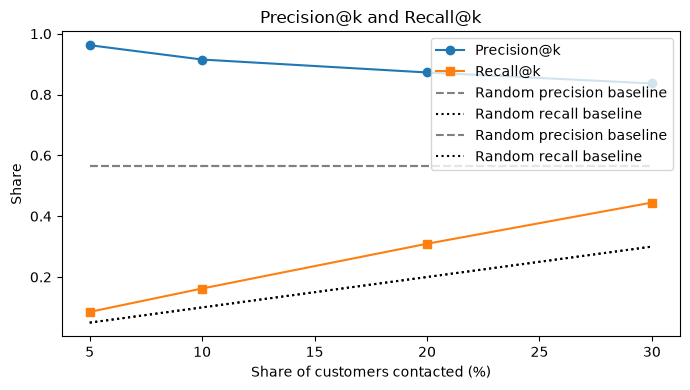

Recommendation: top 10% precision=91.5% and recall=16.2% (97 of 598 churners); top 30% recall=44.5% at precision=83.6%. Start with a high-yield 10% pilot and expand only when capacity and the cost of missed churn justify it.
Default-threshold test recall=0.7391; churners=598; 95% Wilson CI=[0.7025, 0.7727], width=0.0702.


,F0.5,F1,F2
model,,,
Logistic Regression,0.779817,0.764045,0.748899
Tuned Decision Tree,0.773432,0.758204,0.743564
Dummy majority,0.619561,0.722659,0.866918
Dummy always churn,0.619561,0.722659,0.866918


F0.5 favors precision, F2 favors recall. Since missed churn risks losing future contribution while a contact costs only £5 in the stated assumptions, F2 is a reasonable operational emphasis; always validate the actual cost/benefit assumptions with the business.


In [4]:

name = "Logistic Regression"
pred = test_pred[name]
tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
p = tp / (tp + fp) if tp + fp else 0.0
r = tp / (tp + fn) if tp + fn else 0.0
f1_manual = 2 * p * r / (p + r) if p + r else 0.0
print(f"Q9 manual F1=2PR/(P+R)={f1_manual:.4f}; sklearn={f1_score(y_test, pred, zero_division=0):.4f}")
print(f"For precision=1.00 and recall=.01: arithmetic mean={(1 + .01) / 2:.3f}; F1={2 * 1 * .01 / (1 + .01):.4f}. "
      "The harmonic mean stays low because almost all actual churners are missed.")

for model_name in models:
    print(f"Q10 {model_name} classification report")
    print(classification_report(y_test, test_pred[model_name], zero_division=0))
print("Macro average weights each class equally; weighted average weights each class by its support, so the majority "
      "class can dominate the weighted score.")

name = "Logistic Regression"
precision_oof, recall_oof, thresholds = precision_recall_curve(y_train, oof_prob[name])
f1_oof = 2 * precision_oof[:-1] * recall_oof[:-1] / np.maximum(precision_oof[:-1] + recall_oof[:-1], 1e-15)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, precision_oof[:-1], label="Precision")
ax.plot(thresholds, recall_oof[:-1], label="Recall")
ax.plot(thresholds, f1_oof, label="F1")
ax.axvline(f1_threshold[name], color="black", linestyle="--", label=f"OOF F1-best={f1_threshold[name]:.3f}")
ax.set(xlabel="Probability threshold (OOF)", ylabel="Metric", title="Logistic Regression: OOF threshold metrics")
ax.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame([
    {"threshold_rule": "default 0.5", **results[name]["test_metrics"]},
    {"threshold_rule": f"OOF F1-best ({f1_threshold[name]:.3f})", **results[name]["test_metrics_f1"]},
]).set_index("threshold_rule").round(4))

recall_k = top_k_table(y_test.to_numpy(), test_prob[name])
display(recall_k.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(recall_k["top_percent"], recall_k["precision_at_k"], marker="o", label="Precision@k")
ax.plot(recall_k["top_percent"], recall_k["recall_at_k"], marker="s", label="Recall@k")
ax.plot(recall_k["top_percent"], recall_k["baseline_precision_at_k"], linestyle="--", color="gray", label="Random precision baseline")
ax.plot(recall_k["top_percent"], recall_k["baseline_recall_at_k"], linestyle=":", color="black", label="Random recall baseline")
ax.plot(recall_k["top_percent"], recall_k["baseline_precision_at_k"], linestyle="--", color="gray", label="Random precision baseline")
ax.plot(recall_k["top_percent"], recall_k["baseline_recall_at_k"], linestyle=":", color="black", label="Random recall baseline")
ax.set(xlabel="Share of customers contacted (%)", ylabel="Share", title="Precision@k and Recall@k")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Recommendation: top 10% precision={precision_k.loc[precision_k['top_percent'] == 10, 'precision_at_k'].iloc[0]:.1%} and "
      f"recall={precision_k.loc[precision_k['top_percent'] == 10, 'recall_at_k'].iloc[0]:.1%} "
      f"({int(precision_k.loc[precision_k['top_percent'] == 10, 'churners_captured'].iloc[0])} of {int(y_test.sum())} churners); "
      f"top 30% recall={precision_k.loc[precision_k['top_percent'] == 30, 'recall_at_k'].iloc[0]:.1%} at "
      f"precision={precision_k.loc[precision_k['top_percent'] == 30, 'precision_at_k'].iloc[0]:.1%}. "
      "Start with a high-yield 10% pilot and expand only when capacity and the cost of missed churn justify it.")

def wilson_interval(successes, trials, z=1.959963984540054):
    phat = successes / trials
    denom = 1 + z**2 / trials
    center = (phat + z**2 / (2 * trials)) / denom
    half = z * math.sqrt(phat * (1 - phat) / trials + z**2 / (4 * trials**2)) / denom
    return center - half, center + half

test_recall = recall_score(y_test, pred, zero_division=0)
recall_ci = wilson_interval(int(tp), int(tp + fn))
print(f"Default-threshold test recall={test_recall:.4f}; churners={int(tp + fn)}; 95% Wilson CI="
      f"[{recall_ci[0]:.4f}, {recall_ci[1]:.4f}], width={recall_ci[1] - recall_ci[0]:.4f}.")

beta_rows = []
all_classifier_results = {**results, **dummy_results}
for model_name, result in all_classifier_results.items():
    beta_rows.append({"model": model_name,
        **{f"F{beta:g}": fbeta_score(y_test, result["test_prediction"], beta=beta, zero_division=0)
           for beta in (0.5, 1, 2)}})
display(pd.DataFrame(beta_rows).set_index("model"))
print("F0.5 favors precision, F2 favors recall. Since missed churn risks losing future contribution while a contact "
      "costs only £5 in the stated assumptions, F2 is a reasonable operational emphasis; always validate the "
      "actual cost/benefit assumptions with the business.")


16. Dono models ke ROC curves CV out-of-fold probabilities par plot karo, AUC legend mein. Decision Tree ka curve staircase jaisa kyun dikhta hai?

17. 1000-sample bootstrap se test AUC ka 95% CI nikaalo, dono models ke liye, aur unke fark ka bhi. Kya fark statistically clear hai?

18. Precision-Recall curve aur Average Precision nikaalo. Random baseline kya hai? Tumhare data mein ROC-AUC aur AP ki kahani kitni alag hai, aur imbalance kitna bada hai isse yeh kaise judta hai?

19. Agar tumhara AUC 0.97+ aaye to tum sabse pehle kya check karoge? (Day 62 ke leakage-free setup ko dhyan mein rakh kar 3-4 lines likho.)

20. Youden’s J se CV par threshold chuno, test par ek baar lagao, aur ROC curve par default 0.5 aur Youden threshold ke operating points mark karo. Yeh threshold business cost wale threshold se alag kyun ho sakta hai?

Section E: RMSE (Day 75)

21. Is example par MAE aur RMSE haath se nikaalo: actual = [50, 60, 70, 80], predicted = [55, 58, 75, 40]. RMSE MAE se bada kyun aaya?

Q15 Logistic Regression: pairwise AUC=0.809426; sklearn=0.809426
Q15 Tuned Decision Tree: pairwise AUC=0.806925; sklearn=0.806925


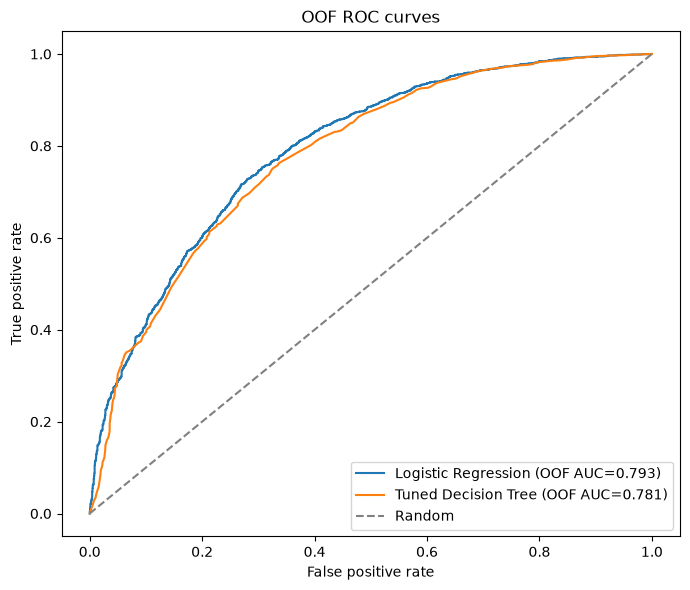

A tree assigns only a limited set of leaf probabilities, so its score has many ties and fewer distinct threshold operating points; the ROC curve therefore appears as a staircase.


,quantity,estimate,95% CI low,95% CI high
0,Logistic Regression,0.8094,0.7830,0.8358
1,Tuned Decision Tree,0.8069,0.7824,0.8324


Paired AUC difference (LogReg - Tree)=0.0025; 95% paired bootstrap CI=[-0.0121, 0.0163]. Difference is statistically clear at this interval level: False.


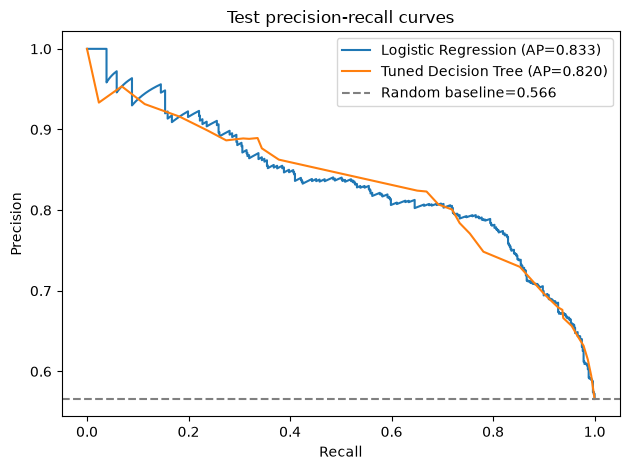

,model,test AP,random AP baseline (prevalence)
0,Logistic Regression,0.8333,0.5658
1,Tuned Decision Tree,0.8205,0.5658


Prevalence=56.575%; majority/minority ratio=1.30:1. ROC-AUC measures ranking across thresholds and can look healthy despite imbalance; AP is tied to positive-class precision/recall and its random baseline is the test prevalence, so AP reveals practical enrichment above the prevalence baseline.


**Q19 leakage check if AUC ≥ 0.97:** first verify that no feature directly encodes `Churned` or the 90-day label rule (especially `Recency`/cutoff-derived fields). Confirm the split was made before fitting imputation, scaling, feature selection, or resampling, and check that one customer cannot appear in both sets. Rebuild features using only information available at the prediction date, then compare train/OOF/test performance. An unusually high score is a prompt to audit the timeline and pipeline—not proof of an excellent model.

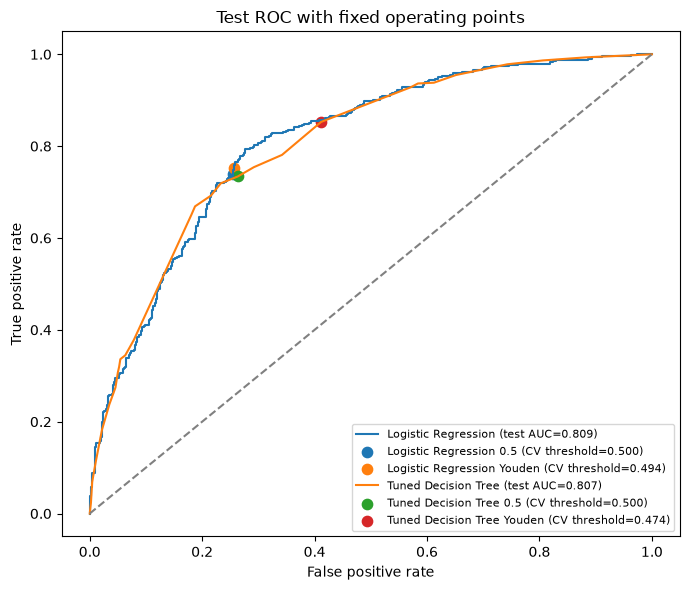

Youden's J maximizes TPR−FPR (equal weight to sensitivity and false-positive rate), whereas a business threshold minimizes expected cost using the actual FN/FP/TP values; unequal costs and contact capacity make the thresholds differ.


In [5]:

def pairwise_auc(y, scores):
    positive = np.asarray(scores)[np.asarray(y) == 1]
    negative = np.asarray(scores)[np.asarray(y) == 0]
    if not len(positive) or not len(negative):
        raise ValueError("AUC requires both classes.")
    comparisons = positive[:, None] - negative[None, :]
    return float(((comparisons > 0).sum() + 0.5 * (comparisons == 0).sum()) / comparisons.size)

for name in models:
    manual_auc = pairwise_auc(y_test, test_prob[name])
    print(f"Q15 {name}: pairwise AUC={manual_auc:.6f}; sklearn={roc_auc_score(y_test, test_prob[name]):.6f}")

fig, ax = plt.subplots(figsize=(7, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_train, oof_prob[name])
    auc = roc_auc_score(y_train, oof_prob[name])
    ax.plot(fpr, tpr, label=f"{name} (OOF AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="OOF ROC curves")
ax.legend()
plt.tight_layout()
plt.show()
print("A tree assigns only a limited set of leaf probabilities, so its score has many ties and fewer distinct "
      "threshold operating points; the ROC curve therefore appears as a staircase.")

def bootstrap_auc(y, score, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    score = np.asarray(score)
    values = []
    while len(values) < n_boot:
        idx = rng.integers(0, len(y), len(y))
        if np.unique(y[idx]).size < 2:
            continue
        values.append(roc_auc_score(y[idx], score[idx]))
    return np.asarray(values)

boot = {name: bootstrap_auc(y_test, test_prob[name], seed=42 + i)
        for i, name in enumerate(models)}
paired_rng = np.random.default_rng(2026)
diffs = []
while len(diffs) < 1000:
    idx = paired_rng.integers(0, len(y_test), len(y_test))
    if np.unique(y_test.to_numpy()[idx]).size < 2:
        continue
    diffs.append(roc_auc_score(y_test.to_numpy()[idx], test_prob["Logistic Regression"][idx]) -
                 roc_auc_score(y_test.to_numpy()[idx], test_prob["Tuned Decision Tree"][idx]))
bootstrap_rows = []
for name, values in boot.items():
    bootstrap_rows.append({"quantity": name, "estimate": roc_auc_score(y_test, test_prob[name]),
                           "95% CI low": np.quantile(values, .025), "95% CI high": np.quantile(values, .975)})
display(pd.DataFrame(bootstrap_rows).round(4))
diffs = np.asarray(diffs)
diff_ci = np.quantile(diffs, [.025, .975])
print(f"Paired AUC difference (LogReg - Tree)={roc_auc_score(y_test, test_prob['Logistic Regression']) - roc_auc_score(y_test, test_prob['Tuned Decision Tree']):.4f}; "
      f"95% paired bootstrap CI=[{diff_ci[0]:.4f}, {diff_ci[1]:.4f}]. "
      f"Difference is statistically clear at this interval level: {not (diff_ci[0] <= 0 <= diff_ci[1])}.")

pr_rows = []
for name in models:
    ap = average_precision_score(y_test, test_prob[name])
    pr_rows.append({"model": name, "test AP": ap, "random AP baseline (prevalence)": prevalence})
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_prob[name])
    plt.plot(recall_curve, precision_curve, label=f"{name} (AP={ap:.3f})")
plt.axhline(y_test.mean(), color="gray", linestyle="--", label=f"Random baseline={y_test.mean():.3f}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Test precision-recall curves"); plt.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(pr_rows).round(4))
print(f"Prevalence={y_test.mean():.3%}; majority/minority ratio="
      f"{max(y_test.value_counts()) / min(y_test.value_counts()):.2f}:1. ROC-AUC measures ranking across thresholds "
      "and can look healthy despite imbalance; AP is tied to positive-class precision/recall and its random baseline "
      "is the test prevalence, so AP reveals practical enrichment above the prevalence baseline.")

display(Markdown(
    "**Q19 leakage check if AUC ≥ 0.97:** first verify that no feature directly encodes `Churned` or the 90-day "
    "label rule (especially `Recency`/cutoff-derived fields). Confirm the split was made before fitting imputation, "
    "scaling, feature selection, or resampling, and check that one customer cannot appear in both sets. Rebuild "
    "features using only information available at the prediction date, then compare train/OOF/test performance. "
    "An unusually high score is a prompt to audit the timeline and pipeline—not proof of an excellent model."
))

fig, ax = plt.subplots(figsize=(7, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, test_prob[name])
    ax.plot(fpr, tpr, label=f"{name} (test AUC={roc_auc_score(y_test, test_prob[name]):.3f})")
    for label, threshold in [("0.5", 0.5), ("Youden", youden_threshold[name])]:
        operating = (test_prob[name] >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, operating, labels=[0, 1]).ravel()
        ax.scatter(fp / (fp + tn), tp / (tp + fn), s=55,
                   label=f"{name} {label} (CV threshold={threshold:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Test ROC with fixed operating points")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Youden's J maximizes TPR−FPR (equal weight to sensitivity and false-positive rate), whereas a business "
      "threshold minimizes expected cost using the actual FN/FP/TP values; unequal costs and contact capacity make "
      "the thresholds differ.")


22. FutureSpend target banao (Day 75 jaisa cutoff). DummyRegressor(mean) aur DummyRegressor(median) ka RMSE, MAE aur R² nikaalo. Target ke std se mean-baseline ke RMSE ko compare karo.

23. Linear Regression ko KFold CV par chalao (train RMSE, CV RMSE, std). Baseline se kitna behtar hai?

24. Top 1% spenders hata kar RMSE dobara nikaalo. Kitna girta hai, aur isse RMSE ke baare mein kya pata chalta hai?

25. Churn classifier par RMSE kyun nahi lagta? Ek line mein likho, aur ek aisa project example do jahan RMSE sahi metric hota.

Section F: Conceptual (apne shabdon mein, bina jargon ke)

26. Ek non-technical manager ko samjhao: “Model 90% accurate hai” ka matlab kab sahi hota hai aur kab bhramak. Apne churn data ka example do.

In [6]:

actual = np.array([50, 60, 70, 80])
predicted = np.array([55, 58, 75, 40])
errors = predicted - actual
mae_manual = np.abs(errors).mean()
rmse_manual = np.sqrt(np.mean(errors ** 2))
print("Q21 errors:", errors, "absolute errors:", np.abs(errors), "squared errors:", errors ** 2)
print(f"MAE={mae_manual:.4f}; RMSE={rmse_manual:.4f}; sklearn RMSE="
      f"{np.sqrt(mean_squared_error(actual, predicted)):.4f}. The -40 error is squared, so RMSE penalizes it heavily.")

tx = pd.read_csv(
    DATA / "step4_datatypes_fixed.csv",
    dtype={"Invoice": str, "StockCode": str},
    parse_dates=["InvoiceDate"],
    usecols=["Invoice", "InvoiceDate", "Quantity", "Price", "Customer ID"],
)
tx["LineTotal"] = tx["Quantity"] * tx["Price"]
cutoff = tx["InvoiceDate"].max() - pd.Timedelta(days=90)
future_spend = tx.loc[tx["InvoiceDate"] >= cutoff].groupby("Customer ID")["LineTotal"].sum()
features = pd.read_csv(DATA / "customer_ml_dataset.csv")
features["FutureSpend"] = features["Customer ID"].map(future_spend).fillna(0)
cols = ["Recency", "Frequency", "Monetary_log", "AvgOrderValue", "Tenure", "UniqueProducts", "Region"]
X_reg = pd.get_dummies(features[cols], columns=["Region"], drop_first=True)
idx_tr, idx_te = train_test_split(
    features.index, test_size=.2, random_state=42, stratify=features["Churned"]
)
X_tr, X_te = X_reg.loc[idx_tr], X_reg.loc[idx_te]
y_tr = features.loc[idx_tr, "FutureSpend"]
y_te = features.loc[idx_te, "FutureSpend"]
assert X_tr.shape == X_train.shape and X_te.shape == X_test.shape
assert np.allclose(X_tr.astype(float).to_numpy(), X_train.astype(float).to_numpy())
assert np.allclose(X_te.astype(float).to_numpy(), X_test.astype(float).to_numpy())
print(f"FutureSpend cutoff={cutoff}; split matches classifier data; target is £ per customer over the last 90 days.")

reg_baselines = {
    "Dummy mean": DummyRegressor(strategy="mean"),
    "Dummy median": DummyRegressor(strategy="median"),
}
regression_rows = []
for reg_name, estimator in reg_baselines.items():
    estimator.fit(X_tr, y_tr)
    pred = estimator.predict(X_te)
    regression_rows.append({"model": reg_name,
                            "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
                            "MAE": mean_absolute_error(y_te, pred),
                            "R2": r2_score(y_te, pred)})
reg_base_table = pd.DataFrame(regression_rows).set_index("model")
display(reg_base_table.round(3))
mean_rmse = reg_base_table.loc["Dummy mean", "RMSE"]
print(f"Test target std={y_te.std(ddof=0):.3f}; mean-baseline RMSE={mean_rmse:.3f}. "
      "These are approximately comparable (exact equality holds when the baseline predicts the evaluation-set mean).")

num_cols = ["Recency", "Frequency", "Monetary_log", "AvgOrderValue", "Tenure", "UniqueProducts"]
prep = ColumnTransformer([("scale", StandardScaler(), num_cols)], remainder="passthrough")
linear_reg = Pipeline([("prep", prep), ("model", LinearRegression())])
kf = KFold(n_splits=5, shuffle=True, random_state=42)
reg_cv = cross_validate(
    linear_reg, X_tr, y_tr, cv=kf,
    scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"},
    return_train_score=True,
)
cv_rmse = -reg_cv["test_rmse"]
train_rmse = -reg_cv["train_rmse"].mean()
baseline_cv = cross_validate(
    DummyRegressor(strategy="mean"), X_tr, y_tr, cv=kf,
    scoring="neg_root_mean_squared_error", return_train_score=False,
)
baseline_cv_rmse = -baseline_cv["test_score"].mean()
print(f"Linear regression train RMSE (mean over folds)={train_rmse:.3f}; "
      f"CV RMSE={cv_rmse.mean():.3f} ± {cv_rmse.std(ddof=1):.3f}; "
      f"mean-baseline CV RMSE={baseline_cv_rmse:.3f}; improvement="
      f"{100 * (baseline_cv_rmse - cv_rmse.mean()) / baseline_cv_rmse:.2f}%.")

linear_reg.fit(X_tr, y_tr)
reg_test_pred = np.clip(linear_reg.predict(X_te), 0, None)
rmse_all = np.sqrt(mean_squared_error(y_te, reg_test_pred))
top_cut = y_te.quantile(.99)
keep = y_te <= top_cut
rmse_without_top = np.sqrt(mean_squared_error(y_te[keep], reg_test_pred[keep]))
print(f"Test RMSE all customers={rmse_all:.3f}; after excluding the top 1% of actual test spenders "
      f"(diagnostic only)={rmse_without_top:.3f}; decrease={rmse_all - rmse_without_top:.3f} "
      f"({100 * (rmse_all - rmse_without_top) / rmse_all:.1f}%). A few large misses can dominate squared error.")
display(Markdown(
    "**Timeline caveat:** this follows the Day 75 exercise's exact last-90-day target and saved customer split. "
    "Because the supplied customer feature table is not rebuilt at a pre-cutoff date here, this regression exercise "
    "is illustrative and its future-spend results must not be treated as a leakage-free deployment estimate."
))
print("Q25: RMSE is for numeric predictions, while churn is a categorical 0/1 decision; a valid RMSE example is "
      "predicting a customer's next-quarter spend in pounds.")


Q21 errors: [  5  -2   5 -40] absolute errors: [ 5  2  5 40] squared errors: [  25    4   25 1600]
MAE=13.0000; RMSE=20.3347; sklearn RMSE=20.3347. The -40 error is squared, so RMSE penalizes it heavily.


FutureSpend cutoff=2011-09-10 12:50:00; split matches classifier data; target is £ per customer over the last 90 days.


,RMSE,MAE,R2
model,,,
Dummy mean,4003.933,831.692,-0.000
Dummy median,4052.454,628.724,-0.025


Test target std=4003.384; mean-baseline RMSE=4003.933. These are approximately comparable (exact equality holds when the baseline predicts the evaluation-set mean).


Linear regression train RMSE (mean over folds)=3745.127; CV RMSE=3513.456 ± 1846.117; mean-baseline CV RMSE=3613.599; improvement=2.77%.
Test RMSE all customers=2987.372; after excluding the top 1% of actual test spenders (diagnostic only)=955.571; decrease=2031.801 (68.0%). A few large misses can dominate squared error.


**Timeline caveat:** this follows the Day 75 exercise's exact last-90-day target and saved customer split. Because the supplied customer feature table is not rebuilt at a pre-cutoff date here, this regression exercise is illustrative and its future-spend results must not be treated as a leakage-free deployment estimate.

Q25: RMSE is for numeric predictions, while churn is a categorical 0/1 decision; a valid RMSE example is predicting a customer's next-quarter spend in pounds.


27. Precision aur Recall mein trade-off ko ek real-life example se samjhao (jaise airport security ya spam filter), phir churn project par lagao.

28. ROC-AUC aur F1 mein fark: ek threshold-free hai, ek threshold par depend. Kab kaunsa quote karoge?

29. “Test set dekh kar threshold choose karna kyun galat hai?” ka jawab ek example ke saath do.

30. Apne project ka final metric choose karo (ek headline metric + ek supporting metric) aur 5-6 lines mein justify karo, apne numbers ke reference ke saath.

In [7]:

majority_share = float(y_test.value_counts(normalize=True).max())
print(f"Q26 test churn prevalence={y_test.mean():.1%}; the always-majority accuracy baseline is "
      f"{majority_share:.1%}. A model can claim about 90% accuracy when 90% of cases are correctly labelled, "
      "but if nearly all customers belong to one class, predicting that class for everyone may reach similar "
      "accuracy while finding no churners. Compare with the majority baseline and recall/precision.")
print("Q27 airport security screens more people to miss fewer threats, but creates more harmless delays; "
      "churn outreach has the same trade-off: lower threshold raises recall but also false alarms, unnecessary "
      "offers, and contact workload. Prioritize according to the £50 FN versus £5 FP assumptions and capacity.")
print("Q28 quote ROC-AUC for threshold-independent ranking/model comparison; quote F1 only with the chosen "
      "operating threshold when precision and recall balance at that threshold matters.")
print("Q29 choosing a threshold after seeing test labels is like repeatedly changing an exam answer after the "
      "answer key is revealed: the reported score becomes optimistic and no longer estimates future performance. "
      "Choose on OOF training predictions, lock the rule, then evaluate test once.")
headline = "avg_precision"
print(f"Q30 headline metric: test AP={test_metrics['Logistic Regression'][headline]:.3f}, "
      f"compared with random/majority baseline={y_test.mean():.3f}. Supporting budget metric: "
      f"precision@10%={precision_k.loc[precision_k['top_percent'] == 10, 'precision_at_k'].iloc[0]:.3f}; "
      f"recall@10%={precision_k.loc[precision_k['top_percent'] == 10, 'recall_at_k'].iloc[0]:.3f} "
      f"({int(precision_k.loc[precision_k['top_percent'] == 10, 'churners_captured'].iloc[0])} of {int(y_test.sum())}).\n"
      "AP rewards a useful ranking across thresholds and exceeds its baseline.\n"
      "The 10% list has high precision but reaches only a limited share of churners.\n"
      "Always-churn gets recall 1.0 but offers to everyone, so recall alone is misleading.\n"
      "Keep outreach capacity and the dummy cost baseline in the decision.\n"
      "These test figures are final diagnostics, not a basis for changing the model.")


Q26 test churn prevalence=56.6%; the always-majority accuracy baseline is 56.6%. A model can claim about 90% accuracy when 90% of cases are correctly labelled, but if nearly all customers belong to one class, predicting that class for everyone may reach similar accuracy while finding no churners. Compare with the majority baseline and recall/precision.
Q27 airport security screens more people to miss fewer threats, but creates more harmless delays; churn outreach has the same trade-off: lower threshold raises recall but also false alarms, unnecessary offers, and contact workload. Prioritize according to the £50 FN versus £5 FP assumptions and capacity.
Q28 quote ROC-AUC for threshold-independent ranking/model comparison; quote F1 only with the chosen operating threshold when precision and recall balance at that threshold matters.
Q29 choosing a threshold after seeing test labels is like repeatedly changing an exam answer after the answer key is revealed: the reported score becomes opti

Section G: Mini Challenge

31. Ek function evaluate_classifier(model, X_tr, y_tr, X_te, y_te, cv, cost_fn=50, cost_fp=5, benefit_tp=40) likho jo ek dictionary/table return kare: CV (mean/std) ke accuracy, precision, recall, f1, roc_auc, avg_precision, test ke wahi metrics, CV-chuna F1-best threshold, aur business net value. Dono models par chalao. Yeh Month 5 mein Random Forest aur XGBoost ke liye reuse hoga.

In [8]:

def evaluation_table(model_results, y_test, y_train):
    rows = []
    for name, result in model_results.items():
        row = {"model": name, "F1-best threshold (OOF)": result["threshold_f1"],
               "test net value at F1 threshold (£)": result["test_net_value_f1"]}
        for metric in ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]:
            fold_values = result["fold"][f"test_{metric}"]
            row[f"CV {metric} mean"] = float(np.mean(fold_values))
            row[f"CV {metric} std"] = float(np.std(fold_values, ddof=1))
            test_key = "avg_precision" if metric == "average_precision" else metric
            row[f"test {test_key}"] = result["test_metrics"][test_key]
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")

challenge = evaluation_table(results, y_test, y_train)
baseline_table = evaluation_table(dummy_results, y_test, y_train)
display(challenge.round(4))
display(Markdown("**Baseline rows (same metrics and protocol):**"))
display(baseline_table.round(4))
print("The reusable evaluate_classifier(model, X_tr, y_tr, X_te, y_te, cv, cost_fn=50, cost_fp=5, "
      "benefit_tp=40) function is defined in the setup cell. It returns per-fold CV results, OOF predictions, "
      "the OOF-selected F1/Youden thresholds, test metrics, and threshold-specific business net value.")


,F1-best threshold (OOF),test net value at F1 threshold (£),CV accuracy mean,CV accuracy std,test accuracy,CV precision mean,CV precision std,test precision,CV recall mean,CV recall std,test recall,CV f1 mean,CV f1 std,test f1,CV roc_auc mean,CV roc_auc std,test roc_auc,CV average_precision mean,CV average_precision std,test avg_precision
model,,,,,,,,,,,,,,,,,,,,
Logistic Regression,0.2889,18720.0,0.7217,0.0100,0.7417,0.7731,0.0086,0.7907,0.7200,0.0187,0.7391,0.7455,0.0110,0.7640,0.7938,0.0142,0.8094,0.8197,0.0129,0.8333
Tuned Decision Tree,0.3005,19160.0,0.7160,0.0073,0.7351,0.7524,0.0225,0.7839,0.7455,0.0296,0.7341,0.7482,0.0052,0.7582,0.7805,0.0161,0.8069,0.7899,0.0168,0.8205


**Baseline rows (same metrics and protocol):**

,F1-best threshold (OOF),test net value at F1 threshold (£),CV accuracy mean,CV accuracy std,test accuracy,CV precision mean,CV precision std,test precision,CV recall mean,CV recall std,test recall,CV f1 mean,CV f1 std,test f1,CV roc_auc mean,CV roc_auc std,test roc_auc,CV average_precision mean,CV average_precision std,test avg_precision
model,,,,,,,,,,,,,,,,,,,,
Dummy majority,1.0,21625.0,0.5663,0.0006,0.5658,0.5663,0.0006,0.5658,1.0,0.0,1.0,0.7231,0.0005,0.7227,0.5,0.0,0.5,0.5663,0.0006,0.5658
Dummy always churn,1.0,21625.0,0.5663,0.0006,0.5658,0.5663,0.0006,0.5658,1.0,0.0,1.0,0.7231,0.0005,0.7227,0.5,0.0,0.5,0.5663,0.0006,0.5658


The reusable evaluate_classifier(model, X_tr, y_tr, X_te, y_te, cv, cost_fn=50, cost_fp=5, benefit_tp=40) function is defined in the setup cell. It returns per-fold CV results, OOF predictions, the OOF-selected F1/Youden thresholds, test metrics, and threshold-specific business net value.
